# T22 -- Predicted vs. observed slick footprint, manual check

**Scope.** This notebook is a visualization/inspection artifact only. No scientific
logic is reimplemented -- every KDE footprint below is built by calling directly
into `iste.slick_footprint` (T22), from an `iste.observation.AdaptedParticleSet`
(T07, the upstream observation particles) and synthetic
`iste.forward_propagation.ForwardCandidateMemberRun` records (standing in for real
T21 output). No comparison/error metric (T23), candidate ranking, AIS, or `c_hat*`
is computed anywhere here.

**What this demonstrates.**

- an **observed slick reference** built ONLY from upstream observation particles
  (`README.md` Sec. 21) -- independent of every candidate;
- two candidates' **predicted slick footprints** at `t_obs`, one deliberately close
  to the observed slick and one deliberately far from it, so the predicted-vs-
  observed comparison this footprint layer exists to support is visually obvious;
- clearly separated panels/labels/colour scale, with each predicted panel's
  `candidate_id`/forcing-member identity and `t_obs` shown explicitly.

In [1]:
import os, sys
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import matplotlib.pyplot as plt
import numpy as np

from iste.forward_propagation import ForwardCandidateMemberRun
from iste.observation import adapt_upstream_particles
from iste.slick_footprint import (
    FootprintGridConfig,
    build_observed_slick_footprint,
    build_predicted_slick_footprint,
)

## 1. Observed slick reference (T07 upstream observation particles)

Built ONLY from `iste.observation.adapt_upstream_particles`'s output -- never from a
backward historical particle slice or a candidate's forward run
(`README.md` Sec. 21: "the backward historical particles are not used as the
independent truth reference").

In [2]:
T_S = np.datetime64("2020-01-01T00:00:00", "ns")
T_OBS = np.datetime64("2020-01-01T06:00:00", "ns")
LAT_GRID = np.linspace(17.0, 21.0, 41)
LON_GRID = np.linspace(98.0, 103.0, 51)

rng = np.random.default_rng(9)

n_obs = 40
obs_lat = 19.0 + rng.normal(0.0, 0.03, n_obs)
obs_lon = 100.5 + rng.normal(0.0, 0.05, n_obs)
records = [
    {"particle_id": f"o{i}", "latitude": obs_lat[i], "longitude": obs_lon[i],
     "observation_pixel_id": f"opx-{i % 5}", "timestamp": T_OBS}
    for i in range(n_obs)
]
adapted = adapt_upstream_particles(records)
print(f"observed reference: {adapted.n_particles} upstream observation particles")

observed reference: 40 upstream observation particles


## 2. Two candidates' predicted forward runs (synthetic, standing in for T21)

Candidate A is placed close to the observed slick (a good forward-validation
match); candidate B is displaced well away from it (a poor match) -- so the figure
below makes the predicted-vs-observed comparison obvious at a glance.

In [3]:
def make_run(lat, lon, candidate_id, member_id):
    n = len(lat)
    return ForwardCandidateMemberRun(
        candidate_id=candidate_id, t_s=T_S, t_obs=T_OBS, forward_forcing_member_id=member_id,
        dt_seconds=900.0, n_steps=0, timestamps=np.array([T_OBS], dtype="datetime64[ns]"),
        particle_id=np.array([f"p{i}" for i in range(n)], dtype=object),
        observation_pixel_id=np.array([f"px-{i}" for i in range(n)], dtype=object),
        forcing_member_id=np.zeros(n, dtype=np.int64),
        original_log_weight=np.zeros(n, dtype=np.float64),
        lat=np.asarray(lat, dtype=np.float64).reshape(1, n),
        lon=np.asarray(lon, dtype=np.float64).reshape(1, n),
        valid=np.ones((1, n), dtype=bool),
    )

n_pred = 25
lat_a = 19.05 + rng.normal(0.0, 0.035, n_pred)
lon_a = 100.4 + rng.normal(0.0, 0.06, n_pred)
run_a = make_run(lat_a, lon_a, "2020-01-01T00:00:00_cand000", member_id=0)

lat_b = 20.0 + rng.normal(0.0, 0.03, n_pred)
lon_b = 99.0 + rng.normal(0.0, 0.04, n_pred)
run_b = make_run(lat_b, lon_b, "2020-01-01T00:00:00_cand001", member_id=0)

## 3. T22 footprints

One shared `FootprintGridConfig` (same grid + bandwidth) for the observed reference
and every predicted footprint, so they are directly, visually comparable.

In [4]:
config = FootprintGridConfig(lat_grid=LAT_GRID, lon_grid=LON_GRID, bandwidth_m=4000.0)

observed_fp = build_observed_slick_footprint(adapted, T_OBS, config)
predicted_fp_a = build_predicted_slick_footprint(run_a, config)
predicted_fp_b = build_predicted_slick_footprint(run_b, config)

print(f"observed: n_valid={observed_fp.n_valid_particles} max_density={np.nanmax(observed_fp.density):.4g}")
print(f"cand A:   n_valid={predicted_fp_a.n_valid_particles} max_density={np.nanmax(predicted_fp_a.density):.4g}")
print(f"cand B:   n_valid={predicted_fp_b.n_valid_particles} max_density={np.nanmax(predicted_fp_b.density):.4g}")

observed: n_valid=40 max_density=5.151e-09
cand A:   n_valid=25 max_density=2.087e-09
cand B:   n_valid=25 max_density=6.253e-09


## 4. Visualization: observed reference vs. each candidate's predicted footprint

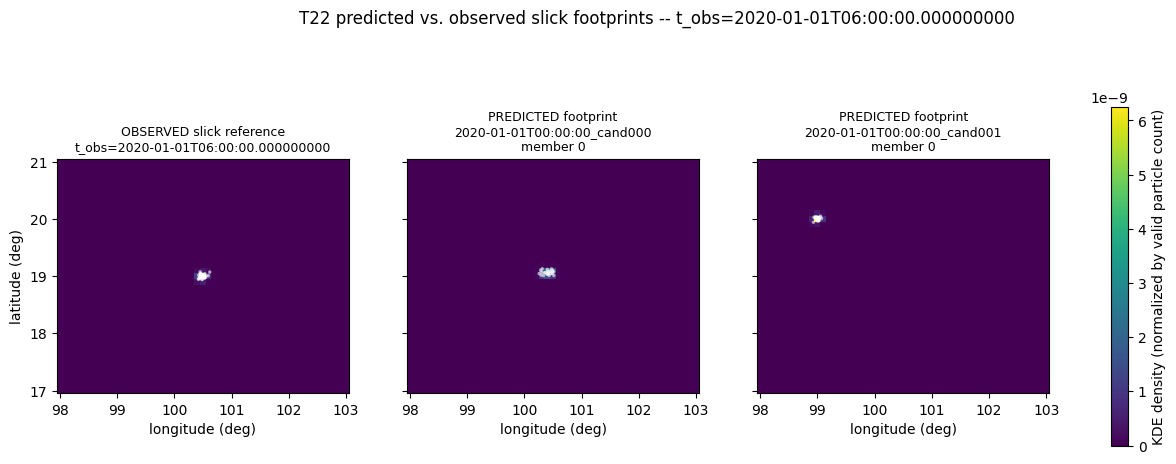

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharex=True, sharey=True)

vmax = max(np.nanmax(observed_fp.density), np.nanmax(predicted_fp_a.density), np.nanmax(predicted_fp_b.density))

for ax, fp, title, obs_pts, pred_pts in [
    (axes[0], observed_fp, f"OBSERVED slick reference\nt_obs={T_OBS}", (obs_lat, obs_lon), None),
    (axes[1], predicted_fp_a, f"PREDICTED footprint\n{run_a.candidate_id}\nmember {run_a.forward_forcing_member_id}", None, (lat_a, lon_a)),
    (axes[2], predicted_fp_b, f"PREDICTED footprint\n{run_b.candidate_id}\nmember {run_b.forward_forcing_member_id}", None, (lat_b, lon_b)),
]:
    mesh = ax.pcolormesh(LON_GRID, LAT_GRID, fp.density, shading="auto", cmap="viridis", vmin=0, vmax=vmax)
    if obs_pts is not None:
        ax.scatter(obs_pts[1], obs_pts[0], s=6, c="white", alpha=0.6, edgecolors="none")
    if pred_pts is not None:
        ax.scatter(pred_pts[1], pred_pts[0], s=6, c="white", alpha=0.6, edgecolors="none")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("longitude (deg)")
    ax.set_aspect("equal")
axes[0].set_ylabel("latitude (deg)")
fig.colorbar(mesh, ax=axes, label="KDE density (normalized by valid particle count)", shrink=0.8)
fig.suptitle(f"T22 predicted vs. observed slick footprints -- t_obs={T_OBS}", fontsize=12)
plt.show()

## Interpretation limits

- This is a **footprint construction** artifact, not a comparison result. No
  spatial-consistency error/score (T23), candidate ranking/filtering, AIS, or
  formal source inference is computed here.
- The predicted KDE is a simulated-slick representation, NOT a source-probability
  map, posterior, or observation likelihood (`README.md` Sec. 20).
- Candidate A visually overlaps the observed reference and candidate B does not --
  by construction in this synthetic demo (to make the comparison obvious) -- this
  says nothing about which candidate is scientifically better; that judgement
  belongs to T23's own explicit, configurable metric.
- Both `FootprintGridConfig`'s `bandwidth_m` and the shared query grid are explicit
  Phase 2 calibration choices (`README.md` Sec. 26), not validated physical
  constants.